# CTA 'L' Access by Community Area

Goal: measure how close each of Chicago's 77 community areas is to the 'L', so we can later compare it with rideshare use (issue #11).

Data used: CTA 'L' stop locations (8pix-ypme) and community area boundaries (igwz-8jzy). See `data/README.md`.

In [1]:
from pathlib import Path
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt

ROOT = Path.cwd()
while not (ROOT / "data").exists() and ROOT != ROOT.parent:
    ROOT = ROOT.parent
SUP = ROOT / "data" / "raw" / "supporting"
(ROOT / "results").mkdir(exist_ok=True)
(ROOT / "docs" / "figures").mkdir(parents=True, exist_ok=True)

areas = gpd.read_file(SUP / "community_areas.geojson")
print(areas.columns.tolist())
num_col = [c for c in areas.columns if c.lower().startswith("area_num")][0]
areas["area"] = areas[num_col].astype(float).astype(int)
areas["name"] = areas["community"].str.title()
areas = areas[["area", "name", "geometry"]].sort_values("area").reset_index(drop=True)
print(len(areas), "community areas")   # should be 77

['community', 'shape_area', 'area_num_1', 'area_numbe', 'shape_len', 'geometry']
77 community areas


In [2]:
stops = pd.read_csv(SUP / "cta_L_stops.csv")
stops.columns = stops.columns.str.strip().str.upper()
print(stops.columns.tolist())

# Location looks like "(41.875, -87.626)": take the latitude and longitude out of it
nums = stops["LOCATION"].astype(str).str.findall(r"-?\d+\.\d+")
stops["lat"] = nums.apply(lambda v: next(float(x) for x in v if 41 < float(x) < 43))
stops["lon"] = nums.apply(lambda v: next(float(x) for x in v if -89 < float(x) < -87))

# one row per station (MAP_ID); a station can serve several lines
LINES = {"RED": "Red", "BLUE": "Blue", "G": "Green", "BRN": "Brown", "P": "Purple",
         "Y": "Yellow", "PNK": "Pink", "O": "Orange"}
for c in LINES:
    stops[c] = stops[c].astype(str).str.strip().str.lower().eq("true")
stations = (stops.groupby("MAP_ID")
            .agg(station=("STATION_NAME", "first"), lat=("lat", "mean"), lon=("lon", "mean"),
                 **{c: (c, "max") for c in LINES})
            .reset_index())
stations["lines"] = stations[list(LINES)].apply(
    lambda r: ", ".join(LINES[c] for c in LINES if r[c]), axis=1)
print(len(stations), "'L' stations")   # about 145
stations.head()

['STOP_ID', 'DIRECTION_ID', 'STOP_NAME', 'STATION_NAME', 'STATION_DESCRIPTIVE_NAME', 'MAP_ID', 'ADA', 'RED', 'BLUE', 'G', 'BRN', 'P', 'Y', 'PNK', 'O', 'LOCATION']
144 'L' stations


,MAP_ID,station,lat,lon,RED,BLUE,G,BRN,P,Y,PNK,O,lines
0,40010,Austin,41.870851,-87.776812,False,True,False,False,False,False,False,False,Blue
1,40020,Harlem/Lake,41.886848,-87.803176,False,False,True,False,False,False,False,False,Green
2,40030,Pulaski,41.885412,-87.725404,False,False,True,False,False,False,False,False,Green
3,40040,Quincy/Wells,41.878723,-87.633740,False,False,False,True,True,False,True,True,"Brown, Purple, Pink, Orange"
4,40050,Davis,42.047710,-87.683543,False,False,False,False,True,False,False,False,Purple


In [3]:
# work in meters (UTM zone 16N covers Chicago)
areas_m = areas.to_crs("EPSG:26916")
st_m = gpd.GeoDataFrame(stations,
                        geometry=gpd.points_from_xy(stations["lon"], stations["lat"]),
                        crs="EPSG:4326").to_crs("EPSG:26916")

# stations inside each area, and how many different lines stop there
inside = gpd.sjoin(st_m, areas_m[["area", "geometry"]], predicate="within")
counts = inside.groupby("area").agg(l_stations=("MAP_ID", "nunique")).reset_index()
lines = inside.groupby("area")[list(LINES)].max().sum(axis=1).rename("l_lines").reset_index()
print(len(stations) - inside["MAP_ID"].nunique(), "stations are outside Chicago (Evanston, Oak Park, ...)")

# distance from the middle of each area to the nearest station
centers = areas_m[["area", "geometry"]].copy()
centers["geometry"] = areas_m.geometry.centroid
near = gpd.sjoin_nearest(centers, st_m[["station", "lines", "geometry"]], distance_col="dist_m")
near = near.drop_duplicates("area")[["area", "station", "lines", "dist_m"]]

access = areas_m[["area", "name"]].copy()
access["area_km2"] = (areas_m.geometry.area / 1e6).round(2)
access = (access.merge(counts, on="area", how="left")
                .merge(lines, on="area", how="left")
                .merge(near, on="area", how="left"))
access[["l_stations", "l_lines"]] = access[["l_stations", "l_lines"]].fillna(0).astype(int)
access["dist_to_L_km"] = (access["dist_m"] / 1000).round(2)
access = access.rename(columns={"station": "nearest_station", "lines": "nearest_station_lines"})
access = access.drop(columns="dist_m")
access.to_csv(ROOT / "results" / "cta_access_by_area.csv", index=False)
print(len(access), "rows saved")   # should be 77
access.sort_values("dist_to_L_km", ascending=False).head(15)

20 stations are outside Chicago (Evanston, Oak Park, ...)
77 rows saved


,area,name,area_km2,l_stations,l_lines,nearest_station,nearest_station_lines,dist_to_L_km
54,55,Hegewisch,13.55,0,0,95th/Dan Ryan,Red,9.44
73,74,Mount Greenwood,7.02,0,0,95th/Dan Ryan,Red,8.00
51,52,East Side,7.73,0,0,95th/Dan Ryan,Red,7.63
53,54,Riverdale,9.13,0,0,95th/Dan Ryan,Red,7.14
45,46,South Chicago,8.66,0,0,87th,Red,6.13
50,51,South Deering,28.20,0,0,95th/Dan Ryan,Red,5.73
52,53,West Pullman,9.22,0,0,95th/Dan Ryan,Red,5.47
74,75,Morgan Park,8.53,0,0,95th/Dan Ryan,Red,5.19
69,70,Ashburn,12.58,0,0,Midway,Orange,5.16
17,18,Montclare,2.56,0,0,Oak Park,Green,4.71


There are 144 'L' stations in the file, and 20 of them are outside Chicago (in places like Evanston and Oak Park), so 124 stations are inside the 77 community areas. The areas farthest from the 'L' are Hegewisch (9.44 km to the nearest station), Mount Greenwood (8.00 km) and East Side (7.63 km). For 9 of the 15 farthest areas, the closest station is 95th/Dan Ryan, the last stop on the Red Line.

In [4]:
print("Areas with no 'L' station inside:", (access["l_stations"] == 0).sum())
print("Median distance to the nearest station:", access["dist_to_L_km"].median(), "km")
access.sort_values("dist_to_L_km").head(10)

Areas with no 'L' station inside: 35
Median distance to the nearest station: 1.25 km


,area,name,area_km2,l_stations,l_lines,nearest_station,nearest_station_lines,dist_to_L_km
31,32,Loop,4.30,16,7,Adams/Wabash,"Green, Brown, Purple, Pink, Orange",0.10
20,21,Avondale,5.13,1,1,Belmont,Blue,0.11
36,37,Fuller Park,1.85,2,1,47th,Red,0.18
21,22,Logan Square,9.29,3,1,California,Blue,0.21
2,3,Uptown,6.04,3,2,Wilson,"Red, Purple",0.22
67,68,Englewood,7.95,2,2,Halsted,Green,0.24
39,40,Washington Park,3.93,1,1,Garfield,Green,0.31
0,1,Rogers Park,4.76,4,3,Morse,Red,0.38
6,7,Lincoln Park,8.20,2,3,Fullerton,"Red, Brown, Purple",0.38
7,8,Near North Side,7.12,7,3,Chicago,"Brown, Purple",0.38


35 of the 77 community areas, almost half, have no 'L' station inside them. The median distance from the middle of an area to the nearest station is 1.25 km, roughly a 15-minute walk. The best-served area is the Loop, with 16 stations and 7 different lines.

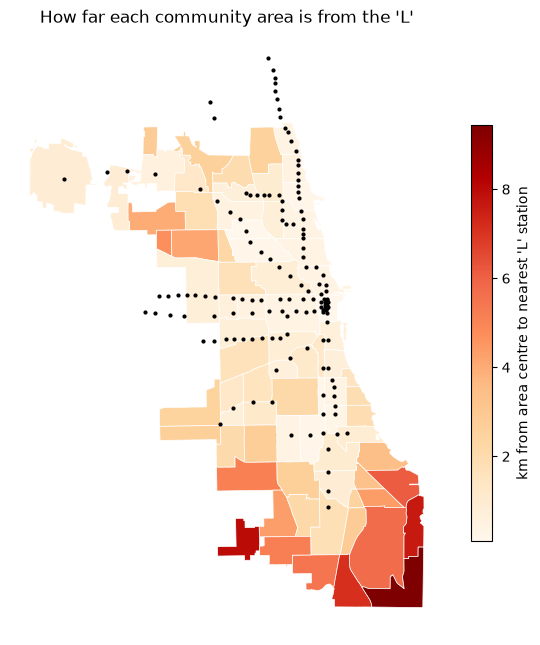

In [5]:
m = areas_m.merge(access[["area", "dist_to_L_km"]], on="area")
ax = m.plot(column="dist_to_L_km", cmap="OrRd", legend=True, figsize=(7, 9),
            edgecolor="white", linewidth=0.5,
            legend_kwds={"label": "km from area centre to nearest 'L' station", "shrink": 0.6})
st_m.plot(ax=ax, color="black", markersize=4)
ax.set_axis_off()
ax.set_title("How far each community area is from the 'L'")
plt.savefig(ROOT / "docs" / "figures" / "cta_distance_map.png", dpi=150, bbox_inches="tight")
plt.show()

The areas farthest from the 'L' are on the Far South Side and Southeast Side (Hegewisch, East Side, Riverdale, South Deering) and the Far Southwest Side (Mount Greenwood, Beverly, Morgan Park), with a smaller group on the Northwest Side (Montclare, Belmont Cragin, Dunning). Downtown has the best coverage: the Brown, Pink, Orange and Purple lines all run around the Loop and each stop 8 times inside it, and the Red Line serves both the Loop and the Near North Side.

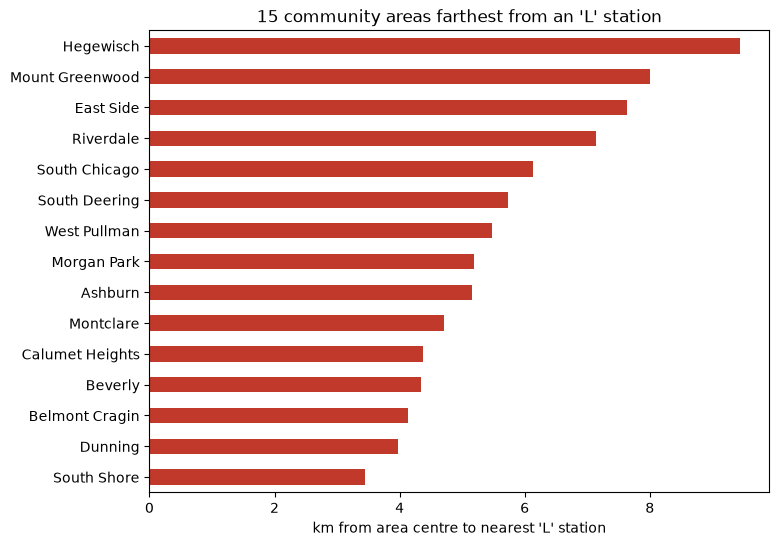

In [6]:
far = access.sort_values("dist_to_L_km", ascending=False).head(15).set_index("name")
ax = far["dist_to_L_km"].sort_values().plot(kind="barh", figsize=(8, 6), color="#c0392b",
        title="15 community areas farthest from an 'L' station")
ax.set_xlabel("km from area centre to nearest 'L' station")
ax.set_ylabel("")
plt.savefig(ROOT / "docs" / "figures" / "cta_farthest_areas.png", dpi=150, bbox_inches="tight")
plt.show()

Most of the farthest areas are in one part of the city: 12 of the 15 are on the South Side, and the other 3 are on the Northwest Side. Riverdale stands out because it was the lowest-income area in our Sprint 1 income chart (\$8,201 per person) and it is also 7.14 km from the 'L'. But being far from the 'L' does not always mean low income: Beverly and Mount Greenwood are far away but richer than most areas, while some of the poorest areas, like Englewood and Fuller Park, have a station less than 0.3 km away.

## What this means for the project

- We now have one table with 'L' access for all 77 community areas (`results/cta_access_by_area.csv`) that we can join to the rideshare trips by community area.
- A transit gap needs two things at once: poor 'L' access and a lot of rideshare trips. Areas like Riverdale, South Deering and West Pullman are far from the 'L' and lower-income, so they are the first places to check.
- This only measures the 'L', not buses. Some far areas may have good bus service, and richer far areas like Beverly may mostly drive, so we need to combine distance with income and rideshare use before calling an area a transit gap.